# 07. Устойчивость выводов к seed

Все финальные модели обучены **один раз**, с `seed = 42`. Бутстреп-интервалы в 03–05 учитывают шум выборки групп (какие пользователи и дни попали в неделю), но **не шум обучения**: с другим seed LightGBM возьмёт другие подвыборки строк и признаков (`bagging_fraction`, `feature_fraction` = 0.8) и построит другие деревья.

Предварительная проба на E0 показала: смена seed двигает GAUC на val_b до 0.0013, а различия между наборами признаков — того же порядка (E2 − E0 на test −0.0008).

**Вопрос:** сохраняются ли выводы, если каждую модель обучить с несколькими seed?

**Правила:** параметры — базовые (те, что в финальном сравнении); оцениваем на val_a и val_b; **test не трогаем**.

**Сокращённый вариант из-за железа:** 3 seed — 42, 1, 2. Seed 42 уже обучен в `06_hyperparams` (вариант `base`), здесь обучаются seed 1 и 2: 5 наборов × 2 = 10 обучений, ~15 мин. **Сначала запускается 06.**

In [1]:
import sys, time, resource, pickle, json, gc
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

from src.candidates import load_candidates
from src.selection import catalog, load_matrix
from src.decay import load_decay
from src.metrics import evaluate
from src.models import train_lgb
from src import memguard

ART = ROOT / "artifacts" / "seeds"
ART.mkdir(parents=True, exist_ok=True)
ART_HP = ROOT / "artifacts" / "HP"
res0, res1, res2 = (pickle.load(open(ROOT / "artifacts" / e / "results.pkl", "rb")) for e in ["E0", "E1", "E2"])
SEEDS = [42, 1, 2]

## 1. Данные

Те же пять наборов и тот же способ загрузки, что в `06_hyperparams`: все 94 колонки читаем один раз, храним как numpy float32.

In [ ]:
SETS = {
    "E0": res0["features"],
    "E1": res1["features"],
    "E0 + E1": res1["union_features"],
    "E2": res2["features"],
    "E0 + E2": [*res0["features"], *res2["features"]],
}
ALL = list(dict.fromkeys(f for cols in SETS.values() for f in cols))
E1_ONLY = [f for f in res1["features"] if f not in res0["features"]]

memguard.check(4.0, "загрузка признаков")
cands = load_candidates()
cat = catalog()
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")

t0 = time.perf_counter()
M, y, META = {}, {}, {}
for part in ["train", "val_a", "val_b"]:
    d = cands.filter(pl.col("part") == part)
    m = (load_matrix(d, E1_ONLY, cat)
         .join(load_decay(d, res2["config"]), on="row_id", how="left", maintain_order="left")
         .join(feats0, on="row_id", how="left", maintain_order="left"))
    # метки сопоставляются по позиции — порядок строк обязан совпадать (polars 2.0 join не сохраняет порядок)
    assert m["row_id"].equals(d["row_id"])
   
    M[part] = m.select(ALL).cast(pl.Float32).to_numpy()
    y[part] = d["label"].to_numpy()
    META[part] = d.select("row_id", "uid", "day", "label")
    del m, d
    gc.collect()

del cands, feats0
gc.collect()

COL = {f: i for i, f in enumerate(ALL)}
print(f"загрузка {time.perf_counter() - t0:.0f} с; пиковая память {peak_ram_gb():.1f} ГБ")

загрузка 10 с; пиковая память 3.6 ГБ


## 2. Обучение с seed 1 и 2

Seed 42 не обучаем заново: берём прогнозы варианта `base` из `artifacts/HP/`. Прогнозы каждого прогона сохраняются в `artifacts/seeds/`, при перезапуске готовые пропускаются.

In [ ]:
def pred_path(set_name, seed, part):
    if seed == 42:
        return ART_HP / f"pred_base_{set_name}_{part}.parquet"
    return ART / f"pred_{set_name}_seed{seed}_{part}.parquet"


for set_name in SETS:
    assert pred_path(set_name, 42, "val_b").exists(), "сначала запустите 06_hyperparams"

cost = {}
for set_name, cols in SETS.items():
    idx = [COL[f] for f in cols]

    for seed in SEEDS[1:]:
        if pred_path(set_name, seed, "val_b").exists():
            continue

        memguard.check(2.0, f"{set_name} seed {seed}")
        X_va = M["val_a"][:, idx]
        model, _, sec = train_lgb(M["train"][:, idx], y["train"], X_va, y["val_a"], {"seed": seed})
        cost[f"{set_name}|{seed}"] = sec
        
        for part, X in [("val_a", X_va), ("val_b", M["val_b"][:, idx])]:
            META[part].select("row_id").with_columns(p=pl.Series(model.predict(X))).write_parquet(pred_path(set_name, seed, part))
        
        print(f"{set_name:8s} seed {seed}: деревьев {model.best_iteration}, {sec:.0f} с, память {peak_ram_gb():.1f} ГБ", flush=True)
        del model, X_va
        gc.collect()
        
del M
_ = gc.collect()

## 3. Метрики каждого прогона

Для каждого набора: GAUC на val_a и val_b при трёх seed, среднее и разброс (стандартное отклонение по трём seed).

In [4]:
P = {}
for s in SETS:
    for seed in SEEDS:
        for part in ["val_a", "val_b"]:
            p = pl.read_parquet(pred_path(s, seed, part))
            assert p["row_id"].equals(META[part]["row_id"])
            P[(s, seed, part)] = p["p"].to_numpy()

rows = []
for (s, seed, part), p in P.items():
    r = evaluate(META[part].with_columns(p=pl.Series(p)), "p")
    rows.append({"набор": s, "seed": seed, "часть": part, **{k: r[k] for k in ["gauc", "ndcg@10", "logloss"]}})
runs = pl.DataFrame(rows)

summary = (runs.group_by("набор", "часть", maintain_order=True)
           .agg(pl.col("gauc").mean().alias("GAUC среднее"), pl.col("gauc").std().alias("std по seed"),
                (pl.col("gauc").max() - pl.col("gauc").min()).alias("размах"),
                pl.col("gauc").filter(pl.col("seed") == 42).first().alias("GAUC seed 42")))
display(runs.pivot(on="seed", index=["набор", "часть"], values="gauc").sort("часть", "набор").with_columns(pl.col(pl.Float64).round(4)))
display(summary.sort("часть", "набор").with_columns(pl.col(pl.Float64).round(4)))

набор,часть,42,1,2
str,str,f64,f64,f64
"""E0""","""val_a""",0.574,0.5743,0.5745
"""E0 + E1""","""val_a""",0.5765,0.5766,0.5782
"""E0 + E2""","""val_a""",0.5769,0.5777,0.5788
"""E1""","""val_a""",0.5725,0.5725,0.5726
"""E2""","""val_a""",0.5759,0.5745,0.5747
"""E0""","""val_b""",0.569,0.5701,0.5703
"""E0 + E1""","""val_b""",0.5733,0.5748,0.5739
"""E0 + E2""","""val_b""",0.5762,0.5749,0.5762
"""E1""","""val_b""",0.5692,0.5692,0.5692


набор,часть,GAUC среднее,std по seed,размах,GAUC seed 42
str,str,f64,f64,f64,f64
"""E0""","""val_a""",0.5743,0.0002,0.0005,0.574
"""E0 + E1""","""val_a""",0.5771,0.001,0.0017,0.5765
"""E0 + E2""","""val_a""",0.5778,0.001,0.0019,0.5769
"""E1""","""val_a""",0.5725,0.0,0.0001,0.5725
"""E2""","""val_a""",0.5751,0.0008,0.0014,0.5759
"""E0""","""val_b""",0.5698,0.0007,0.0013,0.569
"""E0 + E1""","""val_b""",0.574,0.0008,0.0015,0.5733
"""E0 + E2""","""val_b""",0.5758,0.0008,0.0013,0.5762
"""E1""","""val_b""",0.5692,0.0,0.0001,0.5692


## 4. Сохраняются ли выводы при каждом seed?

Главные выводы отчёта — разности с E0. Сравниваем пары с **одинаковым** seed (набор − E0 при seed 42, при seed 1, при seed 2) и смотрим, меняется ли знак.

In [5]:
diff = (runs.filter(pl.col("набор") != "E0")
        .join(runs.filter(pl.col("набор") == "E0").select("seed", "часть", pl.col("gauc").alias("g0")), on=["seed", "часть"], how="left")
        .with_columns((pl.col("gauc") - pl.col("g0")).alias("Δ"))
        .pivot(on="seed", index=["набор", "часть"], values="Δ")
        .with_columns(pl.mean_horizontal([str(s) for s in SEEDS]).alias("среднее"),
                      pl.min_horizontal([str(s) for s in SEEDS]).alias("мин"),
                      pl.max_horizontal([str(s) for s in SEEDS]).alias("макс"))
        .with_columns(pl.when(pl.col("мин") > 0).then(pl.lit("всегда +"))
                      .when(pl.col("макс") < 0).then(pl.lit("всегда −")).otherwise(pl.lit("знак меняется")).alias("знак"))
        .sort("часть", "набор"))
display(diff.with_columns(pl.col(pl.Float64).round(4)))

набор,часть,42,1,2,среднее,мин,макс,знак
str,str,f64,f64,f64,f64,f64,f64,str
"""E0 + E1""","""val_a""",0.0025,0.0022,0.0037,0.0028,0.0022,0.0037,"""всегда +"""
"""E0 + E2""","""val_a""",0.0028,0.0033,0.0043,0.0035,0.0028,0.0043,"""всегда +"""
"""E1""","""val_a""",-0.0015,-0.0018,-0.0019,-0.0017,-0.0019,-0.0015,"""всегда −"""
"""E2""","""val_a""",0.0019,0.0002,0.0002,0.0008,0.0002,0.0019,"""всегда +"""
"""E0 + E1""","""val_b""",0.0043,0.0047,0.0036,0.0042,0.0036,0.0047,"""всегда +"""
"""E0 + E2""","""val_b""",0.0072,0.0048,0.0059,0.006,0.0048,0.0072,"""всегда +"""
"""E1""","""val_b""",0.0002,-0.0009,-0.0011,-0.0006,-0.0011,0.0002,"""знак меняется"""
"""E2""","""val_b""",0.0036,0.0027,0.0019,0.0027,0.0019,0.0036,"""всегда +"""


## 5. Усреднение по seed и бутстреп

Если усреднить прогнозы трёх seed, шум обучения уменьшается. Для усреднённых прогнозов считаем разность с усреднённым E0 и парный бутстреп по группам — так же, как в 03–05 (1000 повторов, 95% ДИ). Рядом — та же разность для одного seed 42.

In [6]:
def group_gauc(d, col):
    return (d.with_columns(r=pl.col(col).rank("average").over("uid", "day"),
                           npos=pl.col("label").sum().over("uid", "day"), n=pl.len().over("uid", "day"))
            .filter((pl.col("npos") > 0) & (pl.col("npos") < pl.col("n")))
            .group_by("uid", "day")
            .agg(g=((pl.col("r") * pl.col("label")).sum() - pl.col("npos").first() * (pl.col("npos").first() + 1) / 2)
                 / (pl.col("npos").first() * (pl.col("n").first() - pl.col("npos").first())))
            .sort("uid", "day")["g"].to_numpy())


boot = []
for part in ["val_a", "val_b"]:
    G = {}
    for s in SETS:
        G[(s, "seed 42")] = group_gauc(META[part].with_columns(p=pl.Series(P[(s, 42, part)])), "p")
        avg = np.mean([P[(s, seed, part)] for seed in SEEDS], axis=0)
        G[(s, "среднее 3 seed")] = group_gauc(META[part].with_columns(p=pl.Series(avg)), "p")
    idx = np.random.default_rng(0).integers(0, len(G[("E0", "seed 42")]), (1000, len(G[("E0", "seed 42")])))
    for s in [s for s in SETS if s != "E0"]:
        for kind in ["seed 42", "среднее 3 seed"]:
            d = G[(s, kind)] - G[("E0", kind)]
            bs = d[idx].mean(1)
            lo, hi = np.quantile(bs, [0.025, 0.975])
            boot.append({"часть": part, "сравнение": f"{s} − E0", "модели": kind, "Δ GAUC": d.mean(),
                         "ДИ низ": lo, "ДИ верх": hi, "значимо": "да" if lo > 0 or hi < 0 else "нет"})
boot = pl.DataFrame(boot)
display(boot.with_columns(pl.col(pl.Float64).round(4)))

часть,сравнение,модели,Δ GAUC,ДИ низ,ДИ верх,значимо
str,str,str,f64,f64,f64,str
"""val_a""","""E1 − E0""","""seed 42""",-0.0015,-0.004,0.0009,"""нет"""
"""val_a""","""E1 − E0""","""среднее 3 seed""",-0.0016,-0.0042,0.0009,"""нет"""
"""val_a""","""E0 + E1 − E0""","""seed 42""",0.0025,0.0004,0.0046,"""да"""
"""val_a""","""E0 + E1 − E0""","""среднее 3 seed""",0.003,0.0012,0.005,"""да"""
"""val_a""","""E2 − E0""","""seed 42""",0.0019,-0.0005,0.0044,"""нет"""
"""val_a""","""E2 − E0""","""среднее 3 seed""",0.0011,-0.0013,0.0035,"""нет"""
"""val_a""","""E0 + E2 − E0""","""seed 42""",0.0028,0.0007,0.0049,"""да"""
"""val_a""","""E0 + E2 − E0""","""среднее 3 seed""",0.0043,0.0022,0.0062,"""да"""
"""val_b""","""E1 − E0""","""seed 42""",0.0002,-0.0025,0.0028,"""нет"""


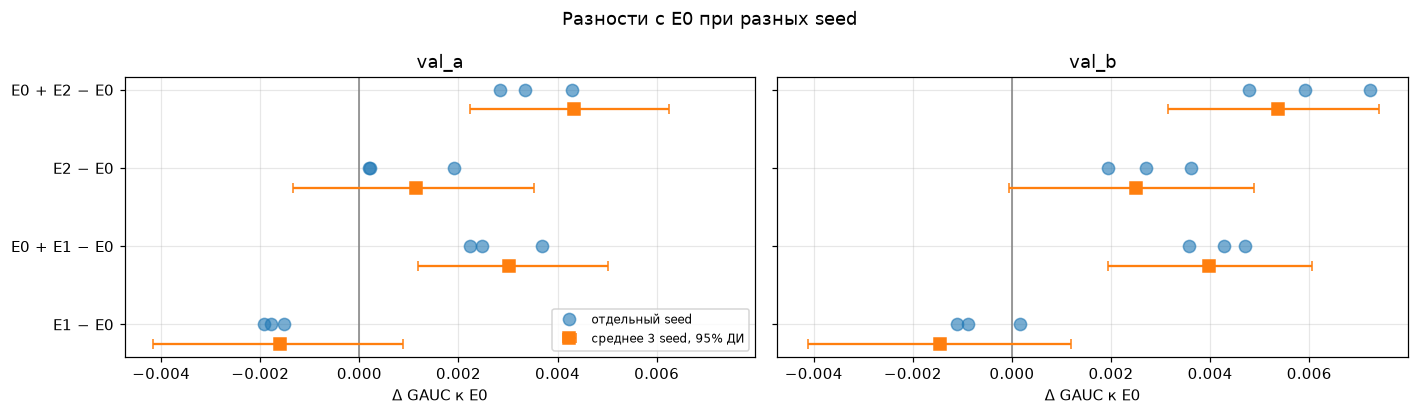

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True, sharey=True)
others = [s for s in SETS if s != "E0"]

for ax, part in zip(axes, ["val_a", "val_b"]):
    ax.axvline(0, color="0.5", lw=1)

    for j, s in enumerate(others):
        dd = diff.filter((pl.col("набор") == s) & (pl.col("часть") == part)).row(0, named=True)
        ax.plot([dd[str(seed)] for seed in SEEDS], [j] * len(SEEDS), "o", color="C0", ms=8, alpha=0.6,
                label="отдельный seed" if j == 0 else None)
        b = boot.filter((pl.col("часть") == part) & (pl.col("сравнение") == f"{s} − E0") & (pl.col("модели") == "среднее 3 seed")).row(0, named=True)
        ax.errorbar(b["Δ GAUC"], j - 0.25, xerr=[[b["Δ GAUC"] - b["ДИ низ"]], [b["ДИ верх"] - b["Δ GAUC"]]],
                    fmt="s", color="C1", ms=8, capsize=3, label="среднее 3 seed, 95% ДИ" if j == 0 else None)
    
    ax.set_yticks(range(len(others)), [f"{s} − E0" for s in others])
    ax.set_title(part)
    ax.set_xlabel("Δ GAUC к E0")
axes[0].legend(loc="lower right", fontsize=8)


fig.suptitle("Разности с E0 при разных seed")
plt.tight_layout()
plt.show()

## 6. Выводы

1. **Шум от seed того же порядка, что различия между наборами.** Стандартное отклонение GAUC по трём seed — до 0.0010, размах — до 0.0019 (E0 + E2 на val_a). E1 почти детерминирован (размах 0.0001): при 10 признаках случайные подвыборки мало что меняют.
2. **Устойчиво: автоматические признаки дополняют ручные.** E0 + E1 и E0 + E2 лучше E0 **при каждом seed на обеих неделях**, а при усреднении трёх seed разница значима. Это тот же вывод, что держится на test.
3. **«E2 значимо лучше E0 на val_b» отчасти было удачей seed.** С seed 42 значимо. При усреднении трёх seed: +0.0025 [−0.0001; +0.0049], уже незначимо. Причина в том, что для E0 seed 42 оказался худшим на val_b (0.5690 против 0.5701 и 0.5703). На test E2 − E0 = −0.0008 : **усреднение по seed на val_b предсказало бы это правильно.**
4. **E1 чуть хуже E0.** При усреднении разность отрицательна на обеих неделях , хотя и незначимо; seed 42 на val_b дал +0.0002 — тоже удача. На test E1 − E0 = −0.0046, тот же знак.
5. **Урок для методики :** бутстреп по группам не учитывает шум обучения. Сравнивая наборы признаков на одном seed, легко принять удачный seed за эффект. Сравнения стоит делать на прогнозах, усреднённых по нескольким seed (хватает уже трёх), и проверять, сохраняется ли знак при каждом seed.
6. **Стоимость:** 10 обучений — 10 мин, пик памяти 4.0 ГБ.


In [8]:
results = {"seeds": SEEDS, "runs": runs, "summary": summary, "diff_vs_E0": diff, "bootstrap": boot,
           "cost": {"train_s": cost, "peak_ram_gb": peak_ram_gb()}}
with open(ART / "results.pkl", "wb") as f:
    pickle.dump(results, f)
display(results["cost"])

{'train_s': {}, 'peak_ram_gb': 3.5610389709472656}